Max Vehicles Constraint: 21
Coordinates: {0: (159.3, 93.6), 1: (36.7, 78.5), 2: (155.9, 66.9), 3: (119.4, 58.1), 4: (89.2, 37.2), 5: (20.0, 94.0), 6: (91.8, 97.4), 7: (66.7, 28.4), 8: (28.6, 30.5), 9: (130.2, 48.6), 10: (11.3, 44.8), 11: (144.4, 99.4), 12: (187.7, 17.6), 13: (0.2, 1.8), 14: (198.4, 49.4), 15: (123.5, 17.9), 16: (122.3, 36.6), 17: (1.4, 74.4), 18: (4.6, 72.1), 19: (105.0, 30.8), 20: (80.0, 54.3), 21: (9.3, 50.9), 22: (194.8, 63.6), 23: (46.6, 25.0), 24: (18.1, 59.0), 25: (123.7, 97.9), 26: (76.5, 48.7), 27: (196.6, 90.6), 28: (93.4, 43.4), 29: (172.0, 35.0), 30: (136.1, 64.5), 31: (90.1, 66.9), 32: (2.7, 86.4), 33: (188.4, 23.0), 34: (112.7, 49.9), 35: (77.1, 57.2), 36: (3.2, 76.9), 37: (46.2, 4.4), 38: (48.2, 99.5), 39: (136.7, 47.0), 40: (122.0, 28.0), 41: (166.6, 88.3), 42: (34.7, 74.8), 43: (78.2, 95.3), 44: (36.4, 33.1), 45: (151.1, 55.3), 46: (85.0, 57.2), 47: (41.6, 98.0), 48: (113.5, 7.5), 49: (6.3, 30.6), 50: (168.5, 19.1), 51: (90.0, 26.8), 52: (79.0, 48.5), 5

C:\Users\hoksa\AppData\Local\Temp\ipykernel_2316\2210974880.py:150: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


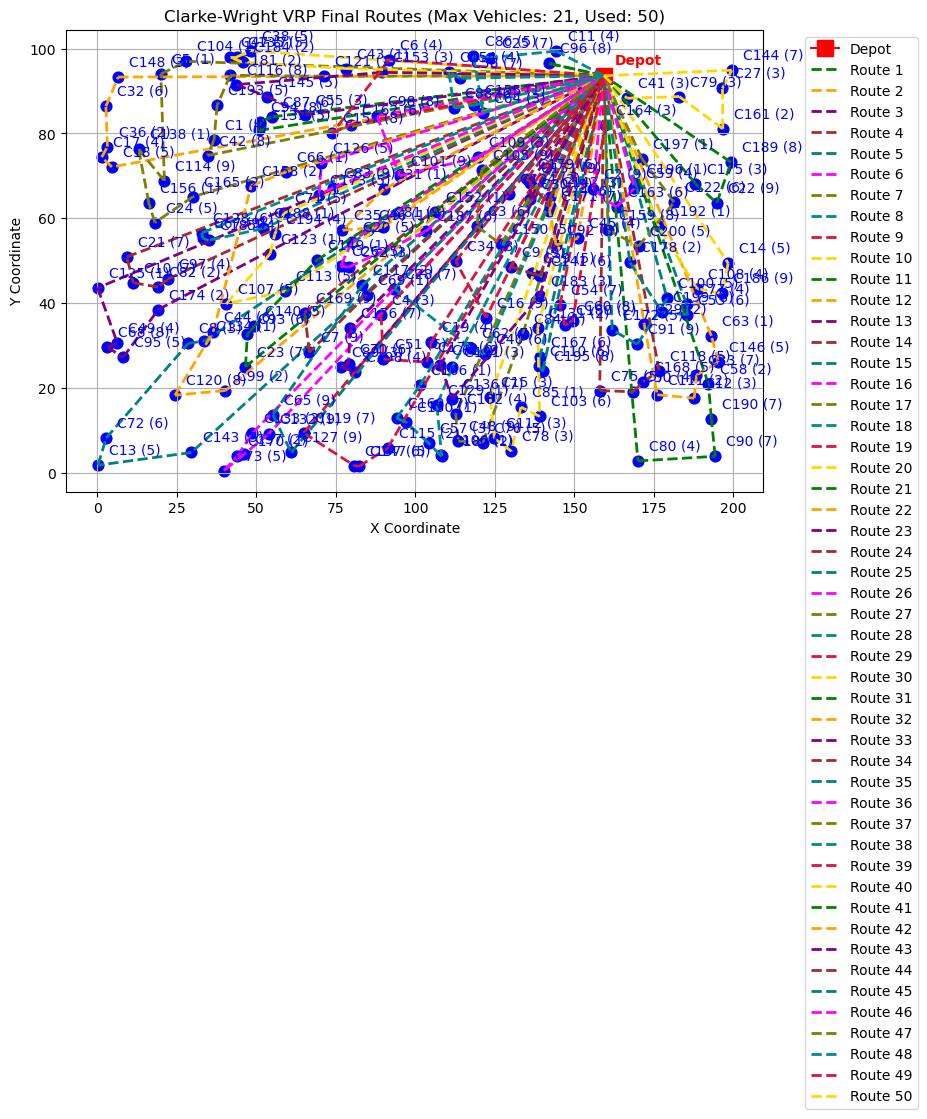

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup Random Generator & Data
rnd = np.random
rnd.seed(42)

n = 200  # Number of customers
capacity = 20  # Vehicle capacity
depot_id = 0

# Define a random integer for maximum available vehicles (between 15 and 30)
max_vehicles = int(rnd.randint(15, 31))

# Coordinates & Demands
xc = rnd.rand(n + 1) * 200
yc = rnd.rand(n + 1) * 100

coords = {i: (round(float(xc[i]), 1), round(float(yc[i]), 1)) for i in range(n + 1)}
demands = {i: int(rnd.randint(1, 10)) for i in range(1, n + 1)}
demands[depot_id] = 0

print(f"Max Vehicles Constraint: {max_vehicles}")
print("Coordinates:", coords)
print("Demands:", demands)

# 2. Helper Functions
def distance_between(point_a, point_b):
    x1, y1 = point_a
    x2, y2 = point_b
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

def find_route_containing(customer_id, routes):
    for index, route in enumerate(routes):
        if customer_id in route:
            return index
    return None

# 3. Clarke-Wright Savings Algorithm with Fleet Size Constraint
def clarke_wright(coords, demands, capacity, depot_id, max_vehicles):
    customer_ids = [i for i in coords if i != depot_id]
    routes = [[c] for c in customer_ids]

    # Calculate Savings
    savings_list = []
    for i in range(len(customer_ids)):
        for j in range(i + 1, len(customer_ids)):
            c1, c2 = customer_ids[i], customer_ids[j]

            dist_depot_1 = distance_between(coords[depot_id], coords[c1])
            dist_depot_2 = distance_between(coords[depot_id], coords[c2])
            dist_1_2 = distance_between(coords[c1], coords[c2])

            savings = dist_depot_1 + dist_depot_2 - dist_1_2
            savings_list.append((round(savings, 2), c1, c2))

    # Sort savings descending
    savings_list.sort(key=lambda x: x[0], reverse=True)

    print("\nSorted Savings List (Savings, Customer 1, Customer 2):")
    for s in savings_list:
        print(s)

    # Merge Routes based on Savings & Constraints
    for savings_amount, c1, c2 in savings_list:
        # Check Vehicle Count Constraint: If total routes are already within vehicle limit,
        # you can either stop or keep optimizing to minimize vehicles further.
        # Here we enforce that the maximum number of final routes cannot exceed max_vehicles.

        r1_idx = find_route_containing(c1, routes)
        r2_idx = find_route_containing(c2, routes)

        # Skip if already in the same route
        if r1_idx == r2_idx:
            continue

        r1, r2 = routes[r1_idx], routes[r2_idx]

        # Ensure both nodes are at exterior endpoints
        c1_at_start, c1_at_end = (r1[0] == c1), (r1[-1] == c1)
        c2_at_start, c2_at_end = (r2[0] == c2), (r2[-1] == c2)

        if not (c1_at_start or c1_at_end) or not (c2_at_start or c2_at_end):
            continue

        # Check vehicle capacity constraint
        if sum(demands[c] for c in r1) + sum(demands[c] for c in r2) > capacity:
            continue

        # Merge routes based on endpoint orientations
        if c1_at_end and c2_at_start:
            merged_route = r1 + r2
        elif c1_at_start and c2_at_end:
            merged_route = r2 + r1
        elif c1_at_end and c2_at_end:
            merged_route = r1 + list(reversed(r2))
        else:  # c1_at_start and c2_at_start
            merged_route = list(reversed(r1)) + r2

        # Remove old routes in decreasing index order to prevent index shifting
        for idx in sorted([r1_idx, r2_idx], reverse=True):
            routes.pop(idx)

        routes.append(merged_route)

    # Final check: enforce vehicle constraint warning if initial demand exceeds max vehicle limit
    if len(routes) > max_vehicles:
        print(f"\n[WARNING] Could not reduce total routes to {max_vehicles}. Current routes needed: {len(routes)}.")
    else:
        print(f"\n[SUCCESS] Solution satisfies maximum vehicle limit: {len(routes)} <= {max_vehicles} vehicles used.")

    # Wrap routes with Depot
    final_routes = [[depot_id] + route + [depot_id] for route in routes]
    return final_routes

# 4. Run Algorithm
final_routes = clarke_wright(coords, demands, capacity, depot_id, max_vehicles)

print("\nFinal Routes After Clarke-Wright Algorithm:")
for i, route in enumerate(final_routes, 1):
    route_demand = sum(demands[c] for c in route)
    print(f"Route {i}: {route} | Total Load: {route_demand}/{capacity}")

# 5. Plot Final Routes
plt.figure(figsize=(9, 6))

# Plot Nodes
for node_id, (x, y) in coords.items():
    if node_id == depot_id:
        plt.plot(x, y, c='r', marker='s', markersize=12, label='Depot')
        plt.annotate("Depot", (x, y), xytext=(8, 8), textcoords="offset points", color='red', fontweight='bold')
    else:
        plt.scatter(x, y, c='b', s=60)
        plt.annotate(f"C{node_id} ({demands[node_id]})", (x, y), xytext=(8, 8), textcoords="offset points", color='blue')

# Plot Route Lines
colors = ['green', 'orange', 'purple', 'brown', 'teal', 'magenta', 'olive', 'darkcyan', 'crimson', 'gold']
for idx, route in enumerate(final_routes):
    color = colors[idx % len(colors)]
    for i in range(len(route) - 1):
        p1, p2 = coords[route[i]], coords[route[i + 1]]
        plt.plot([p1[0], p2[0]], [p1[1], p2[1]], color=color, linestyle='--', linewidth=2,
                 label=f'Route {idx + 1}' if i == 0 else "")

plt.title(f"Clarke-Wright VRP Final Routes (Max Vehicles: {max_vehicles}, Used: {len(final_routes)})")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.grid(True)
plt.show()